In [1]:

# Step 2.2 - Load Training and Validation Data

import pandas as pd
from pathlib import Path

# 1. Locate the project folder
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

# 2. Load training and validation datasets
train_df = pd.read_csv(project_path / "data" / "train.csv")
val_df = pd.read_csv(project_path / "data" / "validation.csv")

# 3. Separate review text and sentiment labels
X_train = train_df["text"]
y_train = train_df["sentiment"]

X_val = val_df["text"]
y_val = val_df["sentiment"]

# 4. Display dataset information
print("Training reviews:", len(X_train))
print("Validation reviews:", len(X_val))

print("\nTraining data preview:")
display(train_df.head())

print("\nTraining sentiment distribution:")
print(y_train.value_counts().sort_index())

print("\nData loaded successfully!")


Training reviews: 3462
Validation reviews: 742

Training data preview:


,text,rating,sentiment
0,Fabulous for price<br />Didnt match but I love...,5.0,2
1,Lasted only Two months,2.0,0
2,"Awful.<br />The brushes from a dollar store, a...",1.0,0
3,As a licensed professional I do not recommend ...,1.0,0
4,I'm really on a kick of trying the whole OZ li...,5.0,2



Training sentiment distribution:
sentiment
0     444
1     348
2    2670
Name: count, dtype: int64

Data loaded successfully!


In [2]:

# Step 2.3 - TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

# 2. Learn vocabulary from training data
# and convert training reviews into numerical vectors
X_train_tfidf = tfidf.fit_transform(X_train)

# 3. Convert validation reviews using the SAME vocabulary
X_val_tfidf = tfidf.transform(X_val)

# 4. Display the matrix dimensions
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)

# 5. Display some vocabulary features
print("\nFirst 20 TF-IDF features:")
print(tfidf.get_feature_names_out()[:20])

# 6. Display TF-IDF values for the first training review
print("\nFirst training review:")
print(X_train.iloc[0])

print("\nNon-zero TF-IDF features for this review:")

first_review_vector = X_train_tfidf[0]

feature_names = tfidf.get_feature_names_out()

for index, value in zip(
    first_review_vector.indices,
    first_review_vector.data
):
    print(feature_names[index], ":", round(value, 4))

print("\nTF-IDF vectorization completed successfully!")


Training TF-IDF shape: (3462, 5000)
Validation TF-IDF shape: (742, 5000)

First 20 TF-IDF features:
['00' '10' '10 minutes' '10 years' '100' '11' '12' '12 99' '13' '14' '15'
 '15 20' '15 minutes' '16' '17' '18' '19' '20' '20 minutes' '20 seconds']

First training review:
Fabulous for price<br />Didnt match but I loved it

Non-zero TF-IDF features for this review:
fabulous : 0.4356
price : 0.2297
br : 0.1704
didnt : 0.4483
match : 0.3955
loved : 0.3591
price br : 0.492

TF-IDF vectorization completed successfully!


In [3]:

# Step 2.4 - Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Create the Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# 2. Train the model
print("Training Logistic Regression model...")

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

# 3. Predict sentiment on validation data
y_val_pred = model.predict(X_val_tfidf)

# 4. Calculate validation accuracy
accuracy = accuracy_score(y_val, y_val_pred)

print("\nValidation Accuracy:", round(accuracy, 4))

# 5. Display detailed classification results
print("\nClassification Report:")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# 6. Display sample predictions
results_df = pd.DataFrame({
    "Review": X_val.values,
    "Actual Sentiment": y_val.values,
    "Predicted Sentiment": y_val_pred
})

print("\nFirst 10 predictions:")
display(results_df.head(10))


Training Logistic Regression model...
Model training completed successfully!

Validation Accuracy: 0.7844

Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.59      0.57        95
     Neutral       0.34      0.50      0.41        74
    Positive       0.92      0.85      0.89       573

    accuracy                           0.78       742
   macro avg       0.60      0.65      0.62       742
weighted avg       0.81      0.78      0.80       742


First 10 predictions:


,Review,Actual Sentiment,Predicted Sentiment
0,This cream product is so thin and virtually we...,2,2
1,The TRESemme’ Shampoo and Conditioner has a ve...,2,1
2,I really like this mascara. It definitely leng...,2,2
3,To strong for my liking so I have to my daught...,1,2
4,Didn't work AND killen my hair,0,0
5,"I cut it, did a curl set and steamed the curls...",2,1
6,I've recently discovered this type of make-up ...,2,2
7,I use these containers for very thing when we ...,2,2
8,Very even and fine spray,2,2
9,I ordered a ‘Boar Bristle Hair Brush with Nylo...,2,2


Confusion Matrix:
[[ 56  19  20]
 [ 15  37  22]
 [ 32  52 489]]


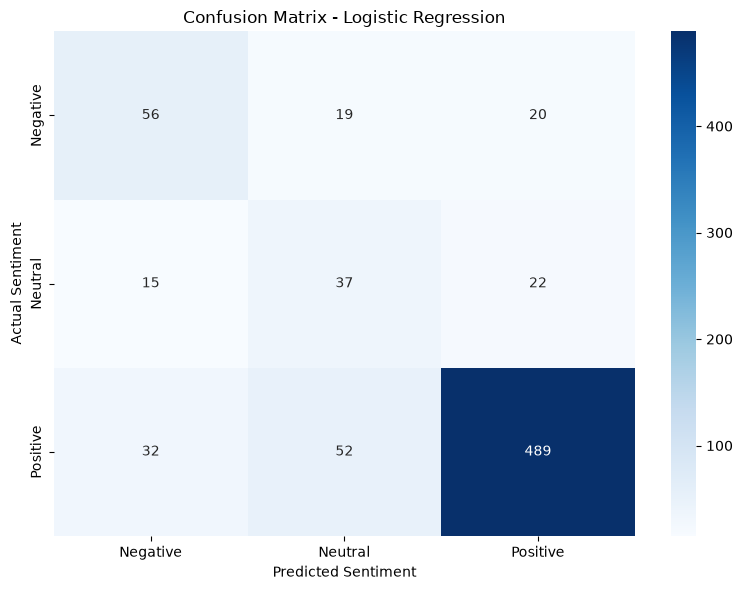


Confusion matrix saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\logistic_regression_confusion_matrix.png


In [4]:

# Step 2.5 - Confusion Matrix for Logistic Regression

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Calculate confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

# 2. Display confusion matrix values
print("Confusion Matrix:")
print(cm)

# 3. Create visualization
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

# 4. Add labels and title
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()

# 5. Save confusion matrix
output_path = project_path / "data" / "logistic_regression_confusion_matrix.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

# 6. Display visualization
plt.show()

print("\nConfusion matrix saved to:", output_path)


In [5]:

# Step 2.6 - Save Trained Logistic Regression Model

import joblib
from pathlib import Path

# 1. Locate the project folder
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

# 2. Create a folder to store trained models
models_path = project_path / "models"
models_path.mkdir(parents=True, exist_ok=True)

# 3. Save the Logistic Regression model
model_file = models_path / "logistic_regression_model.pkl"

joblib.dump(model, model_file)

# 4. Save the TF-IDF vectorizer
tfidf_file = models_path / "tfidf_vectorizer.pkl"

joblib.dump(tfidf, tfidf_file)

# 5. Verify saved files
print("Logistic Regression model saved to:", model_file)
print("TF-IDF vectorizer saved to:", tfidf_file)

print("\nBoth files saved successfully!")


Logistic Regression model saved to: c:\Users\jyothi\sentiment-analysis-nlp\models\logistic_regression_model.pkl
TF-IDF vectorizer saved to: c:\Users\jyothi\sentiment-analysis-nlp\models\tfidf_vectorizer.pkl

Both files saved successfully!


In [6]:

# Step 2.7 - Predict Sentiment for New Customer Reviews

import joblib
import pandas as pd
from pathlib import Path

# 1. Locate project folder
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

# 2. Load saved model
model = joblib.load(
    project_path / "models" / "logistic_regression_model.pkl"
)

# 3. Load saved TF-IDF vectorizer
tfidf = joblib.load(
    project_path / "models" / "tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer loaded successfully!")

# 4. Create new customer reviews
new_reviews = [
    "This product is amazing! I absolutely love it.",
    "Terrible quality. Completely disappointed.",
    "The product is okay, nothing special.",
    "Excellent quality and fast delivery.",
    "The packaging was damaged and the product did not work.",
    "Average product. It works but could be better."
]

# 5. Convert review text into numerical features
new_reviews_tfidf = tfidf.transform(new_reviews)

# 6. Predict sentiment
predictions = model.predict(new_reviews_tfidf)

# 7. Calculate predicted probabilities
probabilities = model.predict_proba(new_reviews_tfidf)

# 8. Convert numerical labels into sentiment names
sentiment_labels = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

# 9. Create results table
results = pd.DataFrame({
    "Review": new_reviews,
    "Predicted Sentiment": [
        sentiment_labels[pred] for pred in predictions
    ],
    "Confidence (%)": [
        round(max(prob) * 100, 2)
        for prob in probabilities
    ]
})

# 10. Display predictions
print("\nPredictions for new customer reviews:")
display(results)

print("\nPrediction completed successfully!")


Model and TF-IDF vectorizer loaded successfully!

Predictions for new customer reviews:


,Review,Predicted Sentiment,Confidence (%)
0,This product is amazing! I absolutely love it.,Positive,77.12
1,Terrible quality. Completely disappointed.,Negative,92.42
2,"The product is okay, nothing special.",Negative,37.81
3,Excellent quality and fast delivery.,Positive,77.92
4,The packaging was damaged and the product did ...,Negative,93.89
5,Average product. It works but could be better.,Neutral,41.46



Prediction completed successfully!
